In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_csv("salaries.csv")
df.head()

,Years of Experience,Education Level,Age,Location Factor,Salary
0,29,1,49,7,124204
1,27,3,45,4,125948
2,20,4,41,8,116078
3,14,4,37,5,106486
4,20,3,42,7,113297


In [2]:
df.shape

(1000, 5)

In [3]:
X = df.drop('Salary', axis='columns')
y = df['Salary']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=10)

model_full=LinearRegression()
model_full.fit(X_train, y_train)
model_full.score(X_test, y_test)

0.9525773624816919

In [4]:
model_full.intercept_

np.float64(52608.48760528247)

In [5]:
model_full.coef_

array([2113.98280589, 5007.82035443, -123.21488799, 1487.64526717])

In [7]:
X_test[:1]

,Years of Experience,Education Level,Age,Location Factor
841,38,1,56,9


In [8]:
y_test[:1]

841    151272
Name: Salary, dtype: int64

In [9]:
model_full.intercept_ + model_full.coef_[0]*38 + model_full.coef_[1]*1 + model_full.coef_[2]*56 + model_full.coef_[3]*9

np.float64(144436.42826039353)

In [10]:
model_full.predict(X_test[:1])

array([144436.42826039])

<Axes: xlabel='Age', ylabel='Salary'>

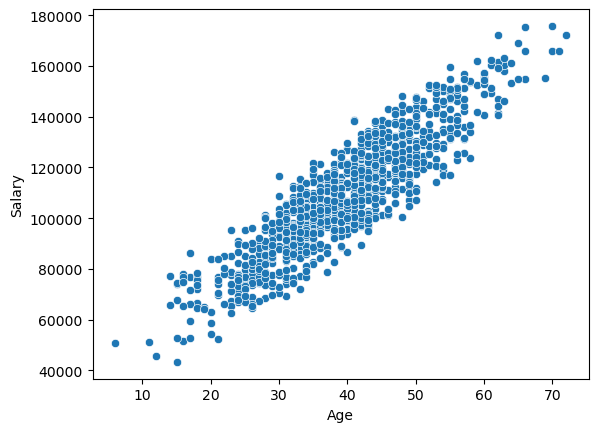

In [13]:
sns.scatterplot(df,x='Age',y='Salary')

in the model the intercept of "Age" is negetive but we can clearly see as the age increases the salary also increase so there is something wrong

<Axes: >

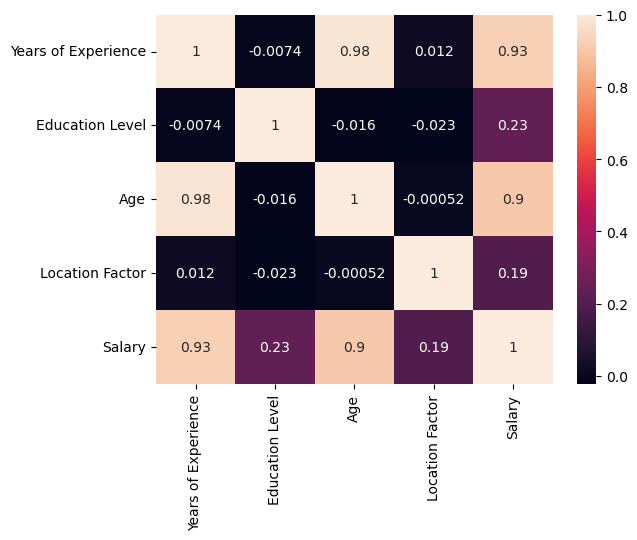

In [18]:
cm=df.corr()
sns.heatmap(cm,annot=True)

In [6]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [19]:
df.values

array([[    29,      1,     49,      7, 124204],
       [    27,      3,     45,      4, 125948],
       [    20,      4,     41,      8, 116078],
       ...,
       [    13,      3,     33,      8, 100478],
       [    19,      2,     40,      2, 100085],
       [    16,      2,     36,      9, 103222]], shape=(1000, 5))

In [21]:
#we will stats model to run vif 

from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    vif_df=pd.DataFrame()
    vif_df['Variable']=data.columns
    vif_df['VIF']=[variance_inflation_factor(data.values, i) for i in range(data.shape[1]) ]
    return vif_df

In [22]:
X = df.drop('Salary', axis="columns")

calculate_vif(X)

,Variable,VIF
0,Years of Experience,22.342087
1,Education Level,5.472969
2,Age,42.201149
3,Location Factor,4.289467


In [23]:
calculate_vif(X.drop(['Age'],axis="columns"))

,Variable,VIF
0,Years of Experience,3.198601
1,Education Level,3.509425
2,Location Factor,3.231181
